# Projet 5 : analyse des crimes et délits en France (2002-2010)

Master 2 ID, parcours IDEAL - Université de Lorraine

BELHADJ Ahlem, FAHMI Othmane, HAMIDI Hafssa, MRHIR Oumaima, NEILI Maram

Les fichiers `faits2002.csv` à `faits2010.csv` sont dans le dossier `data/`.

Démarche suivie :
1. Q1 : K-means directement sur les 103 faits (en profils)
2. ACP pour résumer les 103 faits
3. Q2 : la Corse en individu supplémentaire, CAH de Ward sur les axes, puis regroupement des faits en 16 familles
4. Q3 : évolution de 2002 à 2010

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

## 1. Les données

Un fichier par année. En lignes les 103 catégories de faits, en colonnes les 96 départements (la Corse est coupée en 2A et 2B).

In [ ]:
df = pd.read_csv("data/faits2010.csv", encoding="latin-1", sep=";")
print(df.shape)
df.head()

(103, 97)


,Faits,1,2,3,4,5,6,7,8,9,...,86,87,88,89,90,91,92,93,94,95
0,Règlements de compte entre malfaiteurs,0,0,0,0,0,3,0,0,0,...,0,0,0,0,0,1,3,0,0,1
1,Homicides pour voler et à l'occasion de vols,0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,1,3,0,1
2,Homicides pour d'autres motifs,6,7,2,3,3,27,5,2,2,...,2,3,1,3,3,6,15,15,21,11
3,Tentatives d'homicides pour voler et à l'occas...,1,0,1,0,0,1,0,0,0,...,0,0,0,0,0,2,2,4,4,0
4,Tentatives homicides pour d'autres motifs,9,6,5,0,0,22,4,1,2,...,1,0,3,11,1,29,32,67,33,38


Trois problèmes à régler :
- l'encodage est en latin-1 et le séparateur est `;` ;
- les nombres à partir de 1000 sont écrits avec un espace (« 1 146 »), pandas les lit comme du texte, il faut enlever l'espace avant de convertir ;
- on veut comparer les départements, donc on les met en lignes (transposée).

In [ ]:
df = df.set_index("Faits")
df = df.T                                          # départements en lignes
df = df.replace(r"\s+", "", regex=True)            # "1 146" -> "1146"
df = df.apply(pd.to_numeric, errors="coerce")

print("Valeurs manquantes :", df.isna().sum().sum())
print(df.shape, "-> 96 départements x 103 faits")

Valeurs manquantes : 0
(96, 103) -> 96 départements x 103 faits


In [ ]:
# quelques chiffres pour se faire une idée
total_dep = df.sum(axis=1).sort_values(ascending=False)
print("Départements avec le plus de faits :")
print(total_dep.head())
print("\nDépartements avec le moins de faits :")
print(total_dep.tail())

total_fait = df.sum(axis=0).sort_values(ascending=False)
print("\nFaits les plus rares en France :")
print(total_fait.tail())

Départements avec le plus de faits :
75    238856
13    172445
59    166565
93    142798
69    115632
dtype: int64

Départements avec le moins de faits :
9     4829
46    4765
15    2984
23    2140
48    2081
dtype: int64

Faits les plus rares en France :
Faits
Vols à main armée contre des entreprises de transports de fonds    42
Homicides pour voler et à l'occasion de vols                       36
Attentats à l'explosif contre des biens publics                    30
Prises d'otages à l'occasion de vols                               19
Prises d'otages dans un autre but                                  14
dtype: int64


## 2. Pourquoi travailler sur des profils

Paris a 238 856 faits, la Lozère 2 081. Si on garde les nombres bruts, un grand département a beaucoup de faits partout et l'analyse ne voit que la taille. On le vérifie avec une ACP rapide sur les nombres bruts.

In [ ]:
axe1_brut = PCA().fit_transform(StandardScaler().fit_transform(df))[:, 0]
print("Corrélation axe 1 / total des faits :", round(abs(np.corrcoef(axe1_brut, df.sum(axis=1))[0, 1]), 3))

Corrélation axe 1 / total des faits : 0.996


Corrélation de 0,996 : l'axe 1 ne mesure que la taille du département. On passe donc aux profils : la part de chaque fait dans le total du département. Chaque ligne fait 1, et on compare le type de criminalité, pas le volume.

In [ ]:
df_profil = df.div(df.sum(axis=1), axis=0)

print(df_profil.sum(axis=1).head())
print(df_profil.loc[["75", "48"], ["Usage de stupéfiants", "Vols à la roulotte"]])

1    1.0
2    1.0
3    1.0
4    1.0
5    1.0
dtype: float64
Faits  Usage de stupéfiants  Vols à la roulotte
75                 0.044232            0.051382
48                 0.052859            0.067275


## 3. Q1 : K-means sur les 103 faits

On centre et on réduit les profils (sinon les faits fréquents comme les vols écrasent les autres), puis on cherche le nombre de groupes avec le score de silhouette.

k = 2 : silhouette = 0.102
k = 3 : silhouette = 0.100
k = 4 : silhouette = 0.091


k = 5 : silhouette = 0.056


k = 6 : silhouette = 0.041
k = 7 : silhouette = 0.047


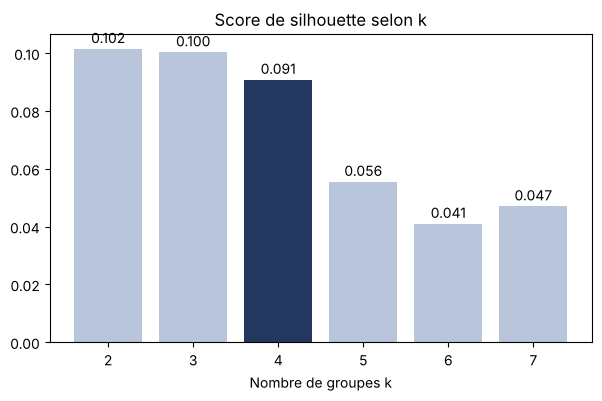

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_profil)

ks = range(2, 8)
scores = []
for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    lab = km.fit_predict(X_scaled)
    scores.append(silhouette_score(X_scaled, lab))
    print(f"k = {k} : silhouette = {scores[-1]:.3f}")

coul = ["#24375F" if k == 4 else "#B8C5DB" for k in ks]
plt.figure(figsize=(7, 4))
plt.bar([str(k) for k in ks], scores, color=coul)
for i, s in enumerate(scores):
    plt.text(i, s + 0.002, f"{s:.3f}", ha="center")
plt.xlabel("Nombre de groupes k")
plt.title("Score de silhouette selon k")
plt.show()

Les scores sont tous très faibles (autour de 0,1) : avec 103 variables les groupes se chevauchent. k = 2 ou 3 donnent un peu mieux mais c'est trop grossier. On garde k = 4, bon compromis entre silhouette et interprétation.

In [ ]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
groupes_q1 = pd.Series(kmeans.fit_predict(X_scaled), index=df_profil.index)

for g in groupes_q1.value_counts().index:
    print(f"Groupe {g} ({(groupes_q1 == g).sum()} dép.) :", groupes_q1[groupes_q1 == g].index.tolist())
    print()

Groupe 0 (58 dép.) : ['1', '2', '7', '8', '10', '11', '14', '16', '17', '18', '21', '22', '25', '26', '27', '28', '29', '30', '33', '34', '35', '36', '37', '38', '40', '41', '42', '44', '45', '47', '49', '51', '54', '56', '57', '59', '60', '62', '63', '64', '66', '67', '68', '71', '72', '73', '74', '76', '80', '81', '82', '83', '84', '85', '86', '87', '88', '90']

Groupe 3 (24 dép.) : ['3', '4', '5', '9', '12', '15', '19', '23', '24', '32', '39', '43', '46', '48', '50', '52', '53', '55', '58', '61', '65', '70', '79', '89']

Groupe 1 (12 dép.) : ['6', '13', '31', '69', '75', '77', '78', '91', '92', '93', '94', '95']

Groupe 2 (2 dép.) : ['2A', '2B']



In [ ]:
# ce qui distingue chaque groupe : écart à la moyenne nationale (en points de %)
profil_groupe = df_profil.groupby(groupes_q1).mean() * 100
ecart = profil_groupe - df_profil.mean() * 100

for g in ecart.index:
    print(f"===== Groupe {g} =====")
    print("Plus :", ecart.loc[g].sort_values(ascending=False).head(3).round(2).to_dict())
    print("Moins :", ecart.loc[g].sort_values().head(3).round(2).to_dict())
    print()

===== Groupe 0 =====
Plus : {'Autres vols simples contre des particuliers dans  des locaux privés': 0.31, "Cambriolages de locaux d'habitations principales": 0.28, 'Vols à la roulotte': 0.27}
Moins : {'Usage de stupéfiants': -0.55, 'Vols violents sans arme contre des femmes sur voie publique ou autre lieu public': -0.14, 'Vols à la tire': -0.13}

===== Groupe 1 =====
Plus : {'Vols à la tire': 1.91, 'Vols à la roulotte': 1.68, 'Vols violents sans arme contre des femmes sur voie publique ou autre lieu public': 1.62}
Moins : {'Autres vols simples contre des particuliers dans  des locaux privés': -2.37, 'Escroqueries et abus de confiances': -1.56, 'Cambriolages de  locaux industriels, commerciaux ou financiers': -1.3}

===== Groupe 2 =====
Plus : {'Escroqueries et abus de confiances': 3.63, "Infractions aux conditions générales d'entrée et de séjour des étrangers": 3.12, 'Vols de véhicules motorisés à 2 roues': 1.31}
Moins : {'Autres vols simples contre des particuliers dans  des locaux pr

Le groupe de 12 : les métropoles (75, 13, 69, 31, 6 et la petite couronne). Plus de vols à la tire, de vols à la roulotte et de vols violents, moins de vols dans les locaux privés et d'escroqueries.

Le groupe de 24 : la France rurale (23, 48, 15, 24...). Plus d'usage de stupéfiants et de cambriolages de locaux, moins de vols à la roulotte.

Le groupe de 2 : la Corse, seule de son côté (plus d'escroqueries et d'infractions sur le séjour des étrangers).

Le groupe de 58 : tous les autres. Les écarts à la moyenne sont minuscules (0,3 point au plus), c'est un groupe fourre-tout.

Avec une silhouette de 0,091 ces groupes se chevauchent beaucoup. C'est pour ça qu'on résume d'abord les 103 faits avec une ACP.

## 4. ACP normée : 96 départements x 103 faits

Pour comprendre pourquoi le K-means marche mal, on résume les 103 faits avec une ACP (sur les mêmes données centrées-réduites).

Axe 1 : 16.47 %   (cumulé 16.5 %)
Axe 2 : 9.26 %   (cumulé 25.7 %)
Axe 3 : 5.96 %   (cumulé 31.7 %)
Axe 4 : 4.61 %   (cumulé 36.3 %)
Axe 5 : 4.34 %   (cumulé 40.6 %)
Axe 6 : 3.35 %   (cumulé 44.0 %)

Critère de Kaiser (lambda > 1) : 30 axes


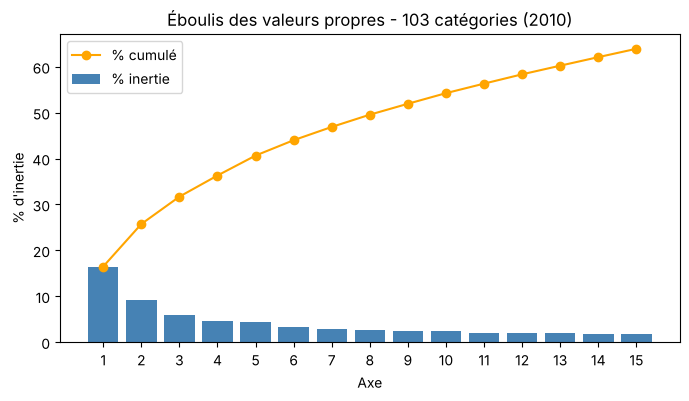

In [ ]:
pca = PCA()
X_pca = pca.fit_transform(X_scaled)
variance = pca.explained_variance_ratio_ * 100
valeurs_propres = pca.explained_variance_

for i in range(6):
    print(f"Axe {i+1} : {variance[i]:.2f} %   (cumulé {variance[:i+1].sum():.1f} %)")
print("\nCritère de Kaiser (lambda > 1) :", (valeurs_propres > 1).sum(), "axes")

plt.figure(figsize=(8, 4))
plt.bar(range(1, 16), variance[:15], color="steelblue", label="% inertie")
plt.plot(range(1, 16), np.cumsum(variance[:15]), "o-", color="orange", label="% cumulé")
plt.xlabel("Axe"); plt.ylabel("% d'inertie"); plt.xticks(range(1, 16))
plt.title("Éboulis des valeurs propres - 103 catégories (2010)")
plt.legend()
plt.show()

Kaiser garde 30 axes, ce qui n'est pas exploitable. L'éboulis casse après l'axe 2. On interprète les axes 1 et 2 (environ 26 % de l'inertie) et on gardera les 5 premiers axes (40 %) pour la CAH.

### Interprétation des axes

Règles du cours : une variable compte pour un axe si |u| > 1/√p (ici 1/√103 = 0,099), un département si |c| > √λ.

In [ ]:
seuil = 1 / np.sqrt(df_profil.shape[1])
print("Seuil variables :", round(seuil, 3))

for a in range(2):
    coeff = pd.Series(pca.components_[a], index=df_profil.columns)
    c = pd.Series(X_pca[:, a], index=df_profil.index)
    s_ind = np.sqrt(valeurs_propres[a])

    print(f"\n======== Axe {a+1} ({variance[a]:.1f} %) ========")
    print("côté + :", coeff[coeff > seuil].sort_values(ascending=False).head(5).round(3).to_dict())
    print("départements + :", c[c > s_ind].sort_values(ascending=False).index.tolist()[:8])
    print("côté - :", coeff[coeff < -seuil].sort_values().head(5).round(3).to_dict())
    print("départements - :", c[c < -s_ind].sort_values().index.tolist()[:8])

Seuil variables : 0.099

======== Axe 1 (16.5 %) ========
côté + : {"Vols violents sans arme contre d'autres victimes": 0.203, 'Vols violents sans arme contre des femmes sur voie publique ou autre lieu public': 0.193, 'Autres vols avec armes blanches': 0.191, 'Vols à la tire': 0.17, 'Autres vols à main armée': 0.148}
départements + : ['93', '94', '75', '13', '95', '92', '91', '6']
côté - : {'Viols sur des mineur(e)s': -0.187, 'Autres vols simples contre des établissements publics ou privés': -0.178, 'Destructions, cruautés et autres délits envers les animaux': -0.174, 'Vols simples sur exploitations agricoles': -0.173, 'Autres destructions et dégradations de biens publics': -0.172}
départements - : ['23', '48', '15', '24', '50', '9', '55', '32']

======== Axe 2 (9.3 %) ========
côté + : {"Attentats à l'explosif contre des biens privés": 0.278, "Emploi d'étranger sans titre de travail": 0.273, 'Règlements de compte entre malfaiteurs': 0.255, 'Travail clandestin': 0.248, "Infractions au 

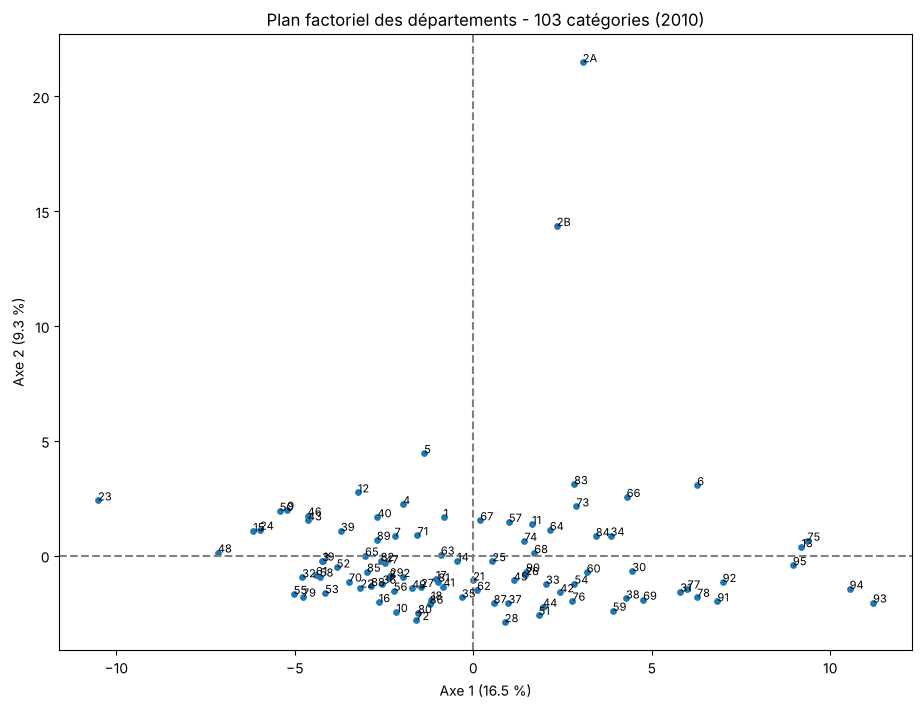

In [ ]:
plt.figure(figsize=(11, 8))
plt.scatter(X_pca[:, 0], X_pca[:, 1], s=15)
for i, dep in enumerate(df_profil.index):
    plt.annotate(dep, (X_pca[i, 0], X_pca[i, 1]), fontsize=8)
plt.axhline(0, color="gray", linestyle="--")
plt.axvline(0, color="gray", linestyle="--")
plt.xlabel(f"Axe 1 ({variance[0]:.1f} %)")
plt.ylabel(f"Axe 2 ({variance[1]:.1f} %)")
plt.title("Plan factoriel des départements - 103 catégories (2010)")
plt.show()

Axe 1 : urbain / rural. À droite les vols violents, vols avec armes blanches, vols à la tire (93, 94, 75, 13). À gauche les vols sur chantiers et exploitations, les délits envers les animaux (23, 48, 15, 24).

Axe 2 : seul le côté positif est rempli (attentats à l'explosif, règlements de comptes, travail clandestin) et il ne concerne presque que 2A et 2B, très loin des autres sur le graphique. L'axe semble décrire seulement la Corse.

## 5. Q2 : le cas de la Corse

On vérifie avec la contribution de chaque département à l'axe 2 : CTR = c² / (n λ).

In [ ]:
n = X_pca.shape[0]
contrib_axe2 = pd.Series(X_pca[:, 1] ** 2 / (n * valeurs_propres[1]) * 100, index=df_profil.index)
print(contrib_axe2.sort_values(ascending=False).head(5).round(2))
print("\n2A + 2B :", round(contrib_axe2[["2A", "2B"]].sum(), 1), "%")

2A    49.94
2B    22.30
5      2.15
83     1.05
6      1.02
dtype: float64

2A + 2B : 72.2 %


La Corse-du-Sud fait à elle seule 50 % de l'axe 2, la Haute-Corse 22 % (72 % à elles deux). Le seuil de prudence du cours est 25 %. La Corse est donc un cas particulier : on la passe en individu supplémentaire (elle est projetée sur les axes mais ne sert plus à les construire).

In [ ]:
corse = ["2A", "2B"]
df_actif = df_profil.drop(index=corse)
df_supp = df_profil.loc[corse]

scaler2 = StandardScaler()
X_actif = scaler2.fit_transform(df_actif)
pca2 = PCA()
X_pca2 = pca2.fit_transform(X_actif)
X_supp = pca2.transform(scaler2.transform(df_supp))     # Corse projetée, pas de fit

variance2 = pca2.explained_variance_ratio_ * 100
for i in range(5):
    print(f"Axe {i+1} : {variance2[i]:.2f} %")
print("5 premiers axes :", round(variance2[:5].sum(), 1), "%")

for a in range(2):
    coeff = pd.Series(pca2.components_[a], index=df_profil.columns)
    print(f"\nAxe {a+1} côté + :", coeff.sort_values(ascending=False).index[:4].tolist())
    print(f"Axe {a+1} côté - :", coeff.sort_values().index[:4].tolist())

Axe 1 : 17.23 %
Axe 2 : 6.66 %
Axe 3 : 5.38 %
Axe 4 : 4.76 %
Axe 5 : 3.78 %
5 premiers axes : 37.8 %

Axe 1 côté + : ["Vols violents sans arme contre d'autres victimes", 'Autres vols avec armes blanches', 'Vols violents sans arme contre des femmes sur voie publique ou autre lieu public', 'Vols à la tire']
Axe 1 côté - : ['Viols sur des mineur(e)s', 'Destructions, cruautés et autres délits envers les animaux', 'Autres vols simples contre des établissements publics ou privés', 'Vols simples sur exploitations agricoles']

Axe 2 côté + : ['Autres coups et blessures volontaires criminels ou correctionnels', 'Violences à dépositaires autorité', 'Outrages à dépositaires autorité', 'Incendies volontaires de biens privés']
Axe 2 côté - : ["Infractions au droit de l'urbanisme et de la construction", 'Autres vols simples contre des particuliers dans des locaux ou lieux publics', "Délits de débits de boissons et infraction à la réglementation sur l'alcool  et le tabac", 'Cambriolages de résidences

L'axe 1 ne change presque pas (17,2 %), l'opposition urbain / rural ne dépendait pas de la Corse. L'axe 2 baisse (6,7 %) mais décrit maintenant tout le continent : violences et dégradations en haut (Nord-Est) contre infractions du littoral et du tourisme en bas (urbanisme, résidences secondaires, séjour des étrangers).

## 6. CAH de Ward sur les 5 premiers axes

On refait les groupes, mais cette fois sur les 5 premiers axes de l'ACP sans la Corse (38 % de l'inertie) et pas sur les 103 faits : les derniers axes contiennent surtout du bruit. Méthode de Ward pour avoir des groupes homogènes.

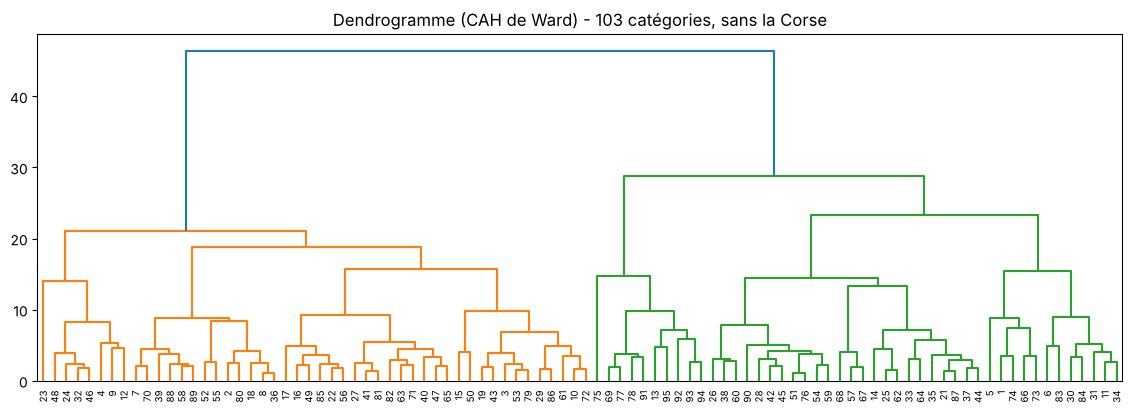

Groupe 1 (48 dép.) : ['2', '3', '4', '7', '8', '9', '10', '12', '15', '16', '17', '18', '19', '22', '23', '24', '27', '29', '32', '36', '39', '40', '41', '43', '46', '47', '48', '49', '50', '52', '53', '55', '56', '58', '61', '63', '65', '70', '71', '72', '79', '80', '81', '82', '85', '86', '88', '89']
Groupe 2 (10 dép.) : ['13', '69', '75', '77', '78', '91', '92', '93', '94', '95']
Groupe 3 (24 dép.) : ['14', '21', '25', '26', '28', '33', '35', '37', '38', '42', '44', '45', '51', '54', '57', '59', '60', '62', '64', '67', '68', '76', '87', '90']
Groupe 4 (12 dép.) : ['1', '5', '6', '11', '30', '31', '34', '66', '73', '74', '83', '84']


In [ ]:
arbre = linkage(X_pca2[:, :5], method="ward")

plt.figure(figsize=(14, 4.5))
dendrogram(arbre, labels=df_actif.index.tolist(), leaf_font_size=7)
plt.title("Dendrogramme (CAH de Ward) - 103 catégories, sans la Corse")
plt.show()

groupes_cah = pd.Series(fcluster(arbre, 4, criterion="maxclust"), index=df_actif.index)
for g in range(1, 5):
    print(f"Groupe {g} ({(groupes_cah == g).sum()} dép.) :", groupes_cah[groupes_cah == g].index.tolist())

In [ ]:
Z_actif = pd.DataFrame(X_actif, index=df_actif.index, columns=df_profil.columns)
moy = Z_actif.groupby(groupes_cah).mean()
for g in moy.index:
    print(f"Groupe {g} : +", moy.loc[g].sort_values(ascending=False).index[:3].tolist())
    print(f"          - ", moy.loc[g].sort_values().index[:3].tolist())

Groupe 1 : + ['Viols sur des mineur(e)s', 'Destructions, cruautés et autres délits envers les animaux', 'Délits au sujet de la garde des mineurs']
          -  ["Vols violents sans arme contre d'autres victimes", 'Autres vols avec armes blanches', 'Vols à la tire']
Groupe 2 : + ["Vols violents sans arme contre d'autres victimes", 'Autres vols avec armes blanches', 'Vols violents sans arme contre des femmes sur voie publique ou autre lieu public']
          -  ['Autres vols simples contre des particuliers dans  des locaux privés', 'Vols simples sur chantier', "Cambriolages d'autres lieux"]
Groupe 3 : + ['Incendies volontaires de biens privés', 'Autres destructions et dégradations de biens privés', "Aide à l'entrée, à la circulation et au séjour des étrangers"]
          -  ['Cambriolages de résidences secondaires', 'Autres infractions à la législation sur les stupéfiants', 'Falsification et usages de cartes de crédit']
Groupe 4 : + ["Emploi d'étranger sans titre de travail", "Aide à l'e

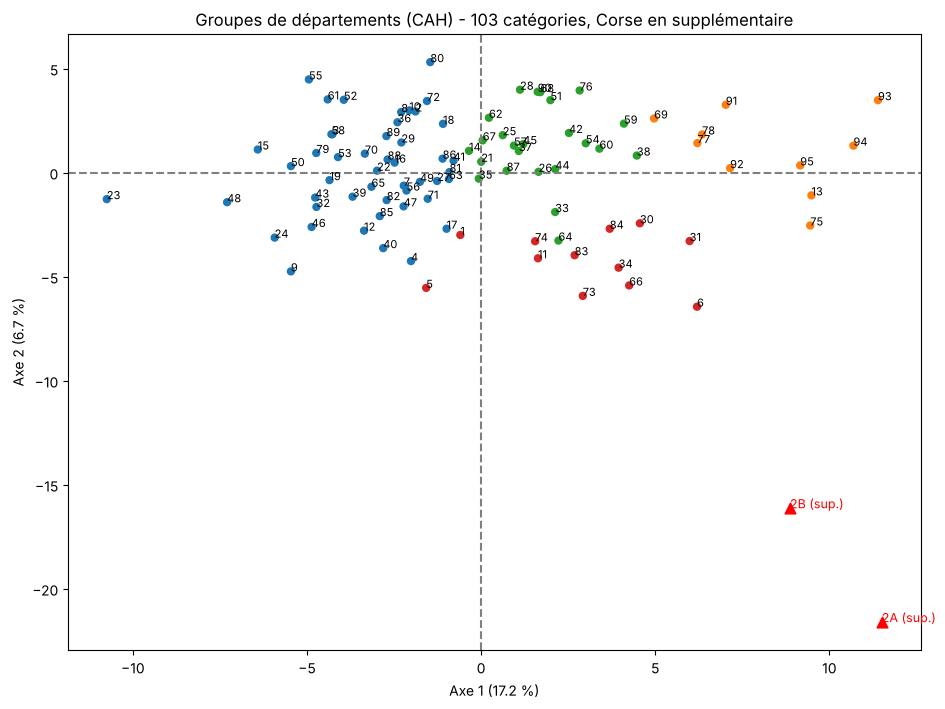

In [ ]:
plt.figure(figsize=(11, 8))
plt.scatter(X_pca2[:, 0], X_pca2[:, 1], c=groupes_cah, cmap="tab10", vmin=1, vmax=10, s=25)
for i, dep in enumerate(df_actif.index):
    plt.annotate(dep, (X_pca2[i, 0], X_pca2[i, 1]), fontsize=8)
plt.scatter(X_supp[:, 0], X_supp[:, 1], marker="^", color="red", s=60)
for i, dep in enumerate(corse):
    plt.annotate(dep + " (sup.)", (X_supp[i, 0], X_supp[i, 1]), fontsize=9, color="red")
plt.axhline(0, color="gray", linestyle="--")
plt.axvline(0, color="gray", linestyle="--")
plt.xlabel(f"Axe 1 ({variance2[0]:.1f} %)")
plt.ylabel(f"Axe 2 ({variance2[1]:.1f} %)")
plt.title("Groupes de départements (CAH) - 103 catégories, Corse en supplémentaire")
plt.show()

On obtient 4 groupes :
1. Rural (48) : délits envers les animaux, vols sur chantiers et exploitations, peu de vols violents (23, 48...)
2. Grandes métropoles (10) : vols violents, vols avec armes blanches (75, 93, 13, 69...)
3. Villes du Nord-Est et de l'Ouest (24) : incendies et dégradations de biens privés (59, 57, 67, 44...)
4. Sud et Alpes (12) : infractions liées aux étrangers, séjour et emploi (6, 83, 73, 34...)

Par rapport au K-means sur les 103 faits, il n'y a plus de groupe fourre-tout de 58 départements.

## 7. 103 catégories c'est trop : 16 familles

Même sans la Corse, le premier plan ne garde qu'environ un quart de l'inertie. Deux raisons : beaucoup de faits sont rares (donc bruités), et beaucoup se ressemblent.

In [ ]:
rares = total_fait[total_fait < 500]
print(len(rares), "faits ont moins de 500 cas en France, par exemple :")
print(rares.sort_values().head(4))

corr = df_actif.corr()
haut = corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1))
print("\nPaires de faits corrélées à plus de 0,7 :", int((haut > 0.7).sum().sum()))

20 faits ont moins de 500 cas en France, par exemple :
Faits
Prises d'otages dans un autre but                  14
Prises d'otages à l'occasion de vols               19
Attentats à l'explosif contre des biens publics    30
Homicides pour voler et à l'occasion de vols       36
dtype: int64

Paires de faits corrélées à plus de 0,7 : 9


On additionne les faits de même nature (dans l'ordre du fichier, numérotés de 1 à 103) pour obtenir 16 familles.

In [ ]:
FAMILLES = {
    "Homicides":                  [1, 2, 3, 4, 5, 6, 51],
    "Coups et menaces":           [7, 8, 9, 10, 11, 12, 13, 14],
    "Vols avec arme":             [15, 16, 17, 18, 19, 20, 21, 22],
    "Vols violents sans arme":    [23, 24, 25, 26],
    "Cambriolages":               [27, 28, 29, 30],
    "Vols simples et recels":     [31, 32, 33, 39, 40, 41, 42, 43, 44],
    "Vols liés aux véhicules":    [34, 35, 36, 37, 38],
    "Violences sexuelles":        [45, 46, 47, 48, 49, 50],
    "Famille et mineurs":         [52, 53, 54],
    "Stupéfiants":                [55, 56, 57, 58],
    "Destructions, dégradations": [62, 63, 64, 65, 66, 67, 68],
    "Étrangers, travail illégal": [69, 70, 71, 93, 94, 95],
    "Atteintes à l'autorité":     [72, 73, 74, 75, 77],
    "Escroqueries et faux":       [81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92],
    "Délits économiques":         [96, 97, 98, 99, 100, 101, 102],
    "Autres délits":              [59, 60, 61, 76, 78, 79, 80, 103],
}
# chaque fait doit être dans une seule famille
assert sorted(sum(FAMILLES.values(), [])) == list(range(1, 104))

def familles(tab):
    return pd.DataFrame({nom: tab.iloc[:, [i - 1 for i in liste]].sum(axis=1)
                         for nom, liste in FAMILLES.items()})

df_fam = familles(df)
profil_fam = df_fam.div(df_fam.sum(axis=1), axis=0)
print(profil_fam.shape)

(96, 16)


In [ ]:
# ACP sur les 16 familles (on garde la Corse pour voir si elle pose encore problème)
scalerF = StandardScaler()
XF = scalerF.fit_transform(profil_fam)
pcaF = PCA()
XF_pca = pcaF.fit_transform(XF)
varF = pcaF.explained_variance_ratio_ * 100
lamF = pcaF.explained_variance_

print("Plan 1-2 :", round(varF[:2].sum(), 1), "%   (103 faits sans Corse :", round(variance2[:2].sum(), 1), "%)")
print("Kaiser :", (lamF > 1).sum(), "axes   (avant : 30)")
print("4 premiers axes :", round(varF[:4].sum(), 1), "%")

contribF = pd.DataFrame(XF_pca[:, :4] ** 2 / (len(XF) * lamF[:4]) * 100, index=profil_fam.index)
print("\nContribution max d'un département à un axe :", round(contribF.max().max(), 1), "% (", contribF.max(axis=1).idxmax(), ")")

Plan 1-2 : 43.9 %   (103 faits sans Corse : 23.9 %)
Kaiser : 5 axes   (avant : 30)
4 premiers axes : 65.9 %

Contribution max d'un département à un axe : 17.2 % ( 2A )


Le premier plan passe de 24 % à 44 %, Kaiser ne garde plus que 5 axes au lieu de 30, et la Corse ne pèse plus que 17 % d'un axe au maximum (contre 50 %). Ses valeurs extrêmes venaient surtout de faits très rares, qui sont maintenant regroupés. Les familles décrivent donc mieux les données.

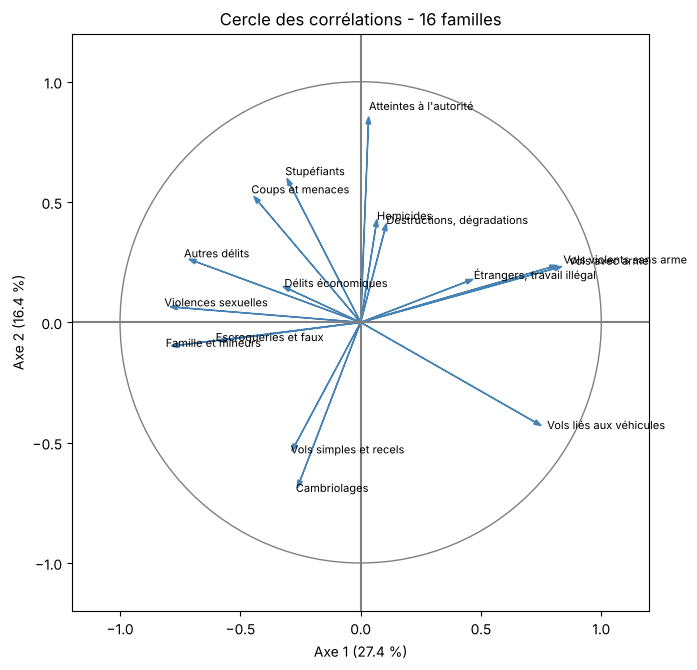

In [ ]:
corrF = pcaF.components_[:2].T * np.sqrt(lamF[:2])

plt.figure(figsize=(7.5, 7.5))
plt.gca().add_patch(plt.Circle((0, 0), 1, fill=False, color="gray"))
for j, nom in enumerate(profil_fam.columns):
    plt.arrow(0, 0, corrF[j, 0], corrF[j, 1], head_width=0.02, color="steelblue")
    plt.text(corrF[j, 0] * 1.07, corrF[j, 1] * 1.07, nom, fontsize=8)
plt.axhline(0, color="gray"); plt.axvline(0, color="gray")
plt.xlim(-1.2, 1.2); plt.ylim(-1.2, 1.2); plt.gca().set_aspect("equal")
plt.xlabel(f"Axe 1 ({varF[0]:.1f} %)"); plt.ylabel(f"Axe 2 ({varF[1]:.1f} %)")
plt.title("Cercle des corrélations - 16 familles")
plt.show()

Axe 1 (27,5 %) : toujours urbain / rural. À droite vols avec arme, vols violents, vols de véhicules ; à gauche violences sexuelles, famille et mineurs, escroqueries (ce sont des parts : dans un département rural il y a peu de vols, donc ces faits pèsent plus).

Axe 2 (16,4 %) : violences en haut (atteintes à l'autorité, stupéfiants, coups et menaces) contre atteintes aux biens en bas (cambriolages, vols simples). Cette opposition n'apparaissait pas avec les 103 faits.

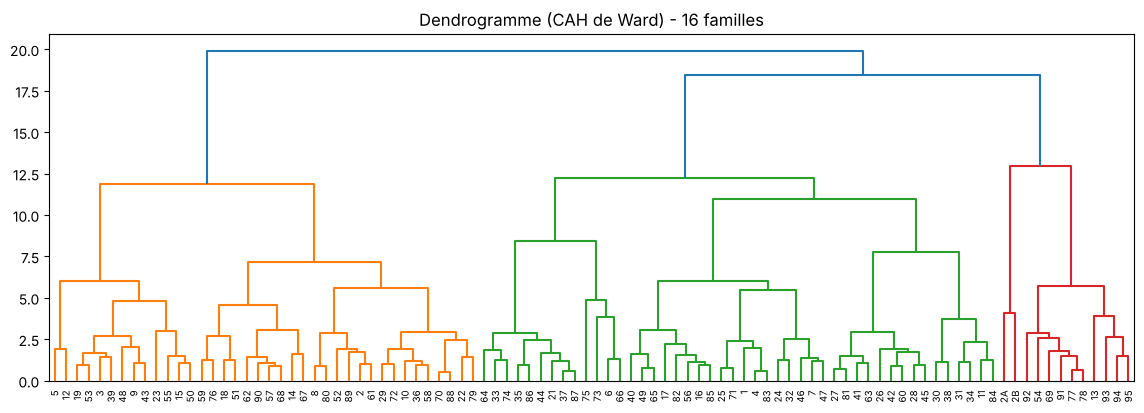

Groupe 1 (38 dép.) : ['2', '3', '5', '8', '9', '10', '12', '14', '15', '18', '19', '22', '23', '29', '36', '39', '43', '48', '50', '51', '52', '53', '55', '57', '58', '59', '61', '62', '67', '68', '70', '72', '76', '79', '80', '88', '89', '90']
Groupe 2 (13 dép.) : ['6', '21', '33', '35', '37', '44', '64', '66', '73', '74', '75', '86', '87']
Groupe 3 (33 dép.) : ['1', '4', '7', '11', '16', '17', '24', '25', '26', '27', '28', '30', '31', '32', '34', '38', '40', '41', '42', '45', '46', '47', '49', '56', '60', '63', '65', '71', '81', '82', '83', '84', '85']
Groupe 4 (2 dép.) : ['2A', '2B']
Groupe 5 (10 dép.) : ['13', '54', '69', '77', '78', '91', '92', '93', '94', '95']


In [ ]:
arbreF = linkage(XF_pca[:, :4], method="ward")
plt.figure(figsize=(14, 4.5))
dendrogram(arbreF, labels=profil_fam.index.tolist(), leaf_font_size=7)
plt.title("Dendrogramme (CAH de Ward) - 16 familles")
plt.show()

groupes_fam = pd.Series(fcluster(arbreF, 5, criterion="maxclust"), index=profil_fam.index)
for g in range(1, 6):
    print(f"Groupe {g} ({(groupes_fam == g).sum()} dép.) :", groupes_fam[groupes_fam == g].index.tolist())

On coupe en 5 groupes : avec 4, la Corse prend un groupe à elle seule et il n'en reste que 3 pour le continent.

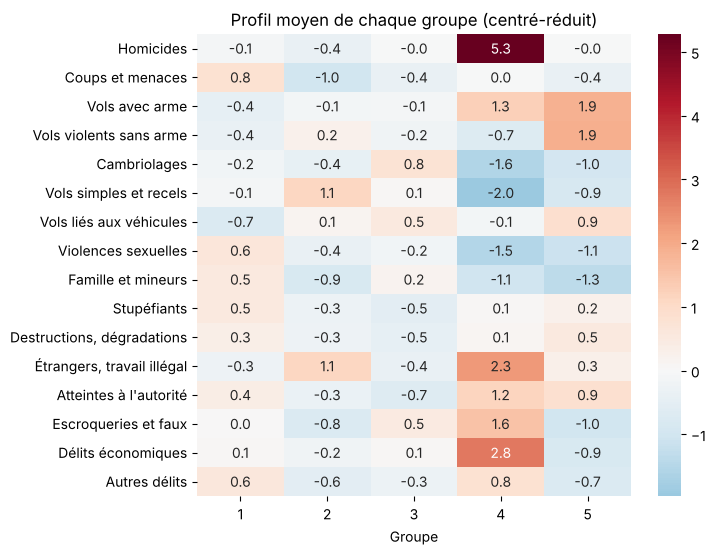

In [ ]:
moyF = pd.DataFrame(XF, index=profil_fam.index, columns=profil_fam.columns).groupby(groupes_fam).mean()

plt.figure(figsize=(7, 6))
sns.heatmap(moyF.T, annot=True, fmt=".1f", cmap="RdBu_r", center=0)
plt.title("Profil moyen de chaque groupe (centré-réduit)")
plt.xlabel("Groupe")
plt.show()

In [ ]:
# comparaison avec les groupes de la CAH sur les 103 faits
print(pd.crosstab(groupes_cah, groupes_fam.drop(index=corse), rownames=["CAH 103 faits"], colnames=["CAH familles"]))

CAH familles    1  2   3  5
CAH 103 faits              
1              28  1  19  0
2               0  1   0  9
3               9  7   7  1
4               1  4   7  0


Les 5 groupes :
1. (38) violences : coups et menaces, violences sexuelles, famille, stupéfiants. Nord-Est (59, 62, 57, 8) et rural du Massif central (23, 48, 15).
2. (13) vols simples et étrangers : Paris et des grandes villes régionales ou touristiques (33, 44, 6, 73).
3. (33) atteintes aux biens : cambriolages, vols de véhicules, escroqueries. Sud et Ouest (34, 83, 24, 85).
4. (2) la Corse, toujours à part.
5. (10) métropoles : vols avec arme, vols violents (petite couronne, 13, 69).

Le tableau croisé montre que les métropoles restent ensemble (9 sur 10, seul Paris part dans le groupe 2 à cause de la part des vols simples). Le groupe rural de la CAH précédente se coupe en deux : 28 départements côté violences, 19 côté atteintes aux biens.

Réponse à Q2 : oui, les caractéristiques qui décrivent le mieux les données ne sont pas les 103 faits, et les groupes changent en partie.

## 8. Q3 : évolution de 2002 à 2010

Question : entre 2002 et 2010, la criminalité a-t-elle changé, en quantité et en nature, en France et dans ses différentes zones ?

On charge les 9 fichiers avec le même nettoyage que pour 2010.

In [ ]:
def charger(annee):
    d = pd.read_csv(f"data/faits{annee}.csv", encoding="latin-1", sep=";")
    d = d.set_index("Faits").T
    d = d.replace(r"\s+", "", regex=True)
    d = d.apply(pd.to_numeric, errors="coerce")
    return d

bruts = {}
profils = {}
for annee in range(2002, 2011):
    bruts[annee] = charger(annee)
    profils[annee] = bruts[annee].div(bruts[annee].sum(axis=1), axis=0)

print(bruts[2002].shape)

(96, 103)


### En quantité

2002    4107811
2003    3971239
2004    3823396
2005    3774151
2006    3723965
2007    3588830
2008    3557872
2009    3520800
2010    3447461
dtype: int64

Évolution 2002-2010 : -16.1 %


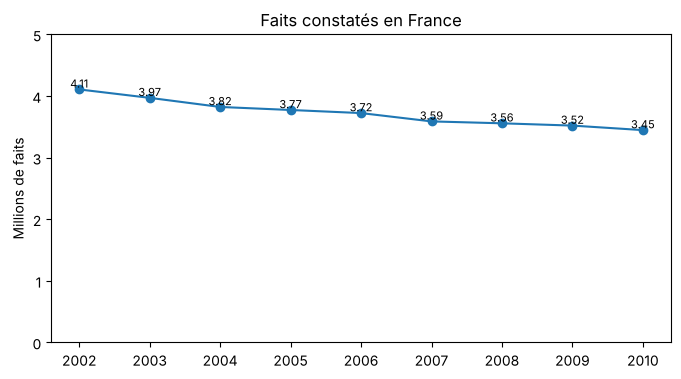

In [ ]:
total_france = pd.Series({a: bruts[a].sum().sum() for a in bruts})
print(total_france)
evol = (total_france[2010] - total_france[2002]) / total_france[2002] * 100
print("\nÉvolution 2002-2010 :", round(evol, 1), "%")

plt.figure(figsize=(8, 4))
plt.plot(total_france.index, total_france.values / 1e6, marker="o")
for a, v in total_france.items():
    plt.text(a, v / 1e6 + 0.03, f"{v/1e6:.2f}", ha="center", fontsize=8)
plt.ylim(0, 5)
plt.ylabel("Millions de faits")
plt.title("Faits constatés en France")
plt.show()

Pour comparer les zones, on a besoin de zones simples et stables. On les fait avec un K-means sur les 2 axes de l'ACP 2010 (103 faits, sans la Corse) : sur ce plan les groupes sont beaucoup mieux séparés (silhouette autour de 0,39 au lieu de 0,09). On prend k = 6, et la Corse est une zone à part.

In [ ]:
X_axes = X_pca2[:, :2]
for k in range(2, 8):
    lab = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_axes)
    print(f"k = {k} : silhouette = {silhouette_score(X_axes, lab):.3f}")

km6 = KMeans(n_clusters=6, random_state=42, n_init=10)
lab6 = pd.Series(km6.fit_predict(X_axes), index=df_actif.index)

# on nomme chaque zone à partir d'un département qu'elle contient
reperes = {"75": "Métropoles", "06": "Sud touristique et frontalier", "6": "Sud touristique et frontalier",
           "59": "Urbain intermédiaire", "80": "Rural Nord / Centre-Est",
           "22": "Rural Ouest / Sud-Ouest", "23": "Rural profond"}
noms = {lab6[d]: nom for d, nom in reperes.items() if d in lab6.index}
print("\nZones nommées :", len(set(noms.values())))

zones = pd.concat([lab6.map(noms), pd.Series("Corse", index=corse)])
print(zones.value_counts())

k = 2 : silhouette = 0.413
k = 3 : silhouette = 0.330
k = 4 : silhouette = 0.372
k = 5 : silhouette = 0.366
k = 6 : silhouette = 0.389


k = 7 : silhouette = 0.370



Zones nommées : 6
Rural Ouest / Sud-Ouest          23
Urbain intermédiaire             22
Rural Nord / Centre-Est          18
Sud touristique et frontalier    12
Rural profond                    10
Métropoles                        9
Corse                             2
Name: count, dtype: int64


Urbain intermédiaire            -18.9
Rural Nord / Centre-Est         -18.7
Rural profond                   -17.5
Rural Ouest / Sud-Ouest         -15.6
Corse                           -15.2
Métropoles                      -14.3
Sud touristique et frontalier   -13.4
dtype: float64


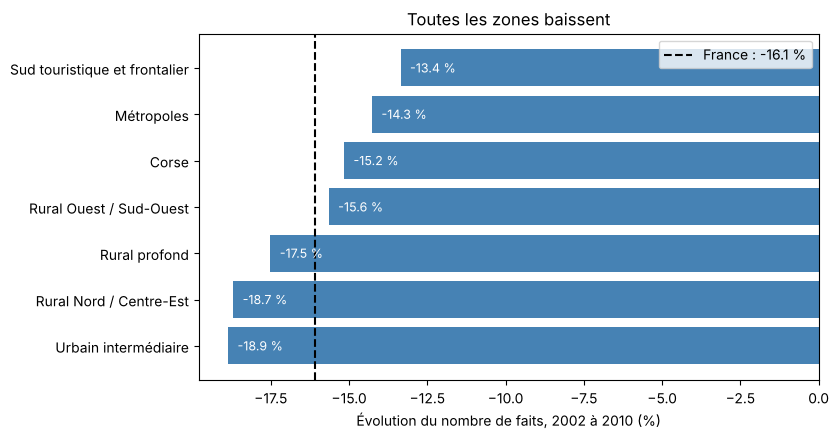

In [ ]:
tableau_zones = pd.DataFrame({a: bruts[a].sum(axis=1).groupby(zones).sum() for a in bruts})
evol_zones = ((tableau_zones[2010] / tableau_zones[2002] - 1) * 100).sort_values()
print(evol_zones.round(1))

plt.figure(figsize=(8, 4.5))
plt.barh(evol_zones.index, evol_zones.values, color="steelblue")
plt.axvline(evol, color="black", linestyle="--", label=f"France : {evol:.1f} %")
for i, v in enumerate(evol_zones.values):
    plt.text(v + 0.3, i, f"{v:.1f} %", va="center", ha="left", color="white", fontsize=9)
plt.xlabel("Évolution du nombre de faits, 2002 à 2010 (%)")
plt.title("Toutes les zones baissent")
plt.legend()
plt.show()

Toutes les zones baissent, de -13,4 % (Sud touristique) à -18,9 % (urbain intermédiaire). Les zones les plus urbaines et touristiques sont celles qui baissent le moins. La Corse finit à -15,2 %, mais avec peu de faits ses pourcentages bougent beaucoup d'une année à l'autre.

### En nature

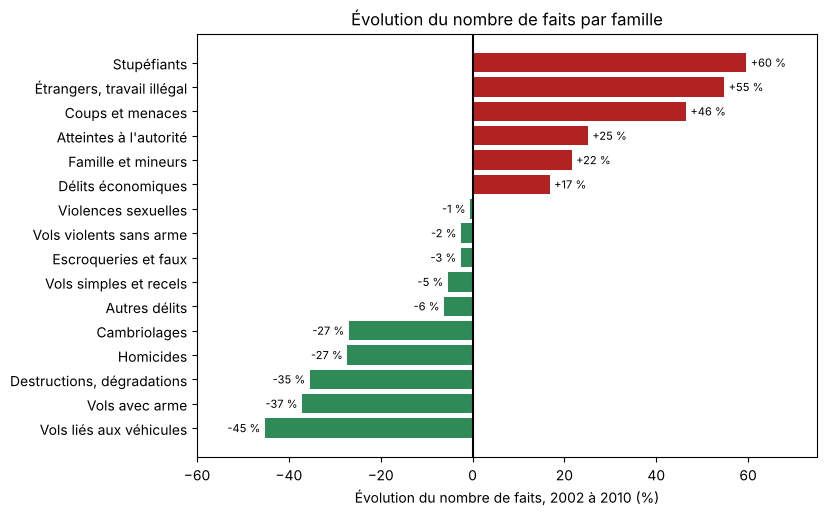

In [ ]:
fam = {a: familles(bruts[a]).sum() for a in bruts}
evol_fam = ((fam[2010] / fam[2002] - 1) * 100).sort_values()

plt.figure(figsize=(8, 5.5))
plt.barh(evol_fam.index, evol_fam.values,
         color=["seagreen" if v < 0 else "firebrick" for v in evol_fam])
for i, v in enumerate(evol_fam.values):
    plt.text(v + (1 if v > 0 else -1), i, f"{v:+.0f} %", va="center",
             ha="left" if v > 0 else "right", fontsize=8)
plt.axvline(0, color="black")
plt.xlim(-60, 75)
plt.xlabel("Évolution du nombre de faits, 2002 à 2010 (%)")
plt.title("Évolution du nombre de faits par famille")
plt.show()

In [ ]:
# le fait le plus fréquent change-t-il ?
part_2002 = bruts[2002].sum() / total_france[2002] * 100
part_2010 = bruts[2010].sum() / total_france[2010] * 100
comparaison = pd.DataFrame({"2002 (%)": part_2002, "2010 (%)": part_2010})
comparaison["écart (points)"] = comparaison["2010 (%)"] - comparaison["2002 (%)"]

print("Top 3 en 2002 :")
print(comparaison.sort_values("2002 (%)", ascending=False).head(3).round(2))
print("\nTop 3 en 2010 :")
print(comparaison.sort_values("2010 (%)", ascending=False).head(3).round(2))

Top 3 en 2002 :
                                                    2002 (%)  2010 (%)  \
Faits                                                                    
Vols à la roulotte                                     11.72      7.87   
Autres vols simples contre des particuliers dan...      7.40      9.01   
Destructions et dégradations de véhicules privés        7.40      4.97   

                                                    écart (points)  
Faits                                                               
Vols à la roulotte                                           -3.85  
Autres vols simples contre des particuliers dan...            1.60  
Destructions et dégradations de véhicules privés             -2.43  

Top 3 en 2010 :
                                                    2002 (%)  2010 (%)  \
Faits                                                                    
Autres vols simples contre des particuliers dan...      7.40      9.01   
Vols à la roulotte           

La baisse cache deux mouvements opposés. Ce qui touche la voiture recule le plus (-45 % pour les vols liés aux véhicules) : les vols à la roulotte passent de 11,7 % à 7,9 % des faits et perdent la 1re place, au profit des vols simples dans les lieux publics. À l'inverse les stupéfiants (+60 %), les infractions sur les étrangers et le travail illégal (+55 %) et les coups et menaces (+46 %) augmentent.

Attention : ce sont des faits constatés. Pour les stupéfiants et les étrangers, la hausse dépend aussi du nombre de contrôles de police.

### Les zones changent-elles de profil ?

On pose les profils de chaque année sur l'ACP de 2010 (transform seulement, pas de nouveau fit), et on suit le centre de chaque zone.

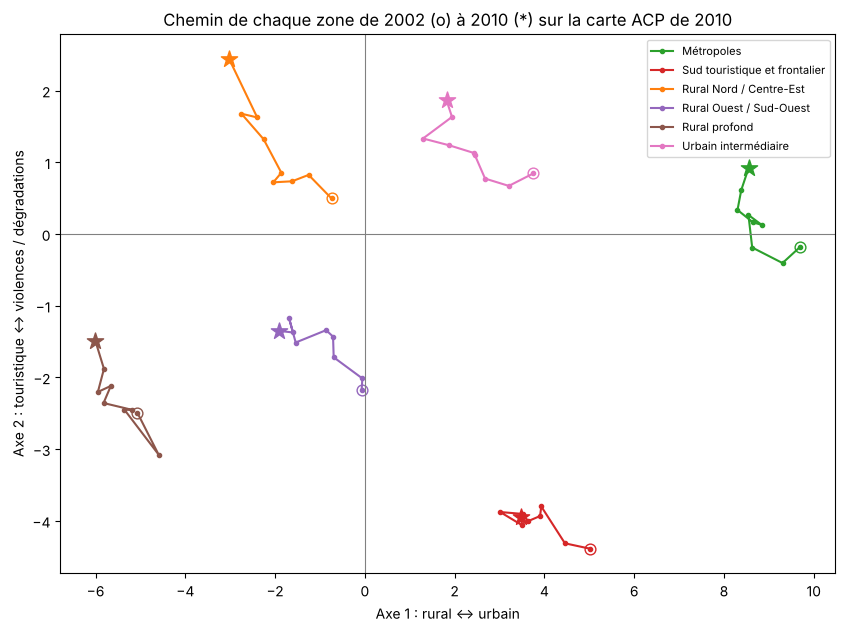

                               Axe 1  Axe 2
Corse                          24.39 -37.76
Métropoles                      9.69  -0.18
Rural Nord / Centre-Est        -0.74   0.50
Rural Ouest / Sud-Ouest        -0.07  -2.18
Rural profond                  -5.07  -2.49
Sud touristique et frontalier   5.01  -4.39
Urbain intermédiaire            3.75   0.85
                               Axe 1  Axe 2
Corse                          10.19 -18.86
Métropoles                      8.55   0.92
Rural Nord / Centre-Est        -3.03   2.45
Rural Ouest / Sud-Ouest        -1.92  -1.35
Rural profond                  -6.00  -1.49
Sud touristique et frontalier   3.48  -3.94
Urbain intermédiaire            1.82   1.86


In [ ]:
centres = {}
for a in range(2002, 2011):
    p = profils[a][df_actif.columns]
    xy = pca2.transform(scaler2.transform(p))[:, :2]
    centres[a] = pd.DataFrame(xy, index=p.index, columns=["Axe 1", "Axe 2"]).groupby(zones).mean()

couleurs_zones = {"Métropoles": "tab:green", "Sud touristique et frontalier": "tab:red",
                  "Rural Nord / Centre-Est": "tab:orange", "Rural Ouest / Sud-Ouest": "tab:purple",
                  "Rural profond": "tab:brown", "Urbain intermédiaire": "tab:pink"}

plt.figure(figsize=(10, 7))
for zone, c in couleurs_zones.items():
    x = [centres[a].loc[zone, "Axe 1"] for a in range(2002, 2011)]
    y = [centres[a].loc[zone, "Axe 2"] for a in range(2002, 2011)]
    plt.plot(x, y, color=c, marker="o", markersize=3, label=zone)
    plt.scatter(x[0], y[0], s=60, facecolors="white", edgecolors=c)    # 2002
    plt.scatter(x[-1], y[-1], s=150, marker="*", color=c)              # 2010
plt.axhline(0, color="gray", linewidth=0.8)
plt.axvline(0, color="gray", linewidth=0.8)
plt.xlabel("Axe 1 : rural <-> urbain")
plt.ylabel("Axe 2 : touristique <-> violences / dégradations")
plt.title("Chemin de chaque zone de 2002 (o) à 2010 (*) sur la carte ACP de 2010")
plt.legend(fontsize=8)
plt.show()

print(centres[2002].round(2))
print(centres[2010].round(2))

Toutes les zones vont vers la gauche : le côté urbain de l'axe 1 contient les vols liés à la voiture, qui reculent partout. Elles montent aussi : le haut de l'axe 2 correspond aux violences et dégradations, dont la part augmente. Mais l'ordre reste le même : métropoles à droite, rural profond à gauche, Sud touristique en bas. Toute la France bouge dans le même sens, les écarts entre zones restent. La Corse (pas sur le graphique, trop loin) se rapproche nettement des autres.

## Synthèse

Q1 : le K-means sur les 103 faits donne 4 groupes, dont un fourre-tout de 58 départements, avec une silhouette faible (0,091). La Corse forme un groupe à elle seule.

Q2 : dans l'ACP, la Corse fait 72 % de l'axe 2 (50 % pour la seule Corse-du-Sud), on la met en individu supplémentaire. La CAH sur les 5 premiers axes donne 4 groupes plus équilibrés. En regroupant les faits en 16 familles, le premier plan passe de 24 % à 44 % : deux axes nets (urbain / rural, violences / atteintes aux biens) et 5 groupes. La Corse reste à part mais ne déforme plus l'analyse.

Q3 : -16,1 % de faits entre 2002 et 2010, dans toutes les zones. La nature change : moins de faits liés à la voiture, plus de violences, d'escroqueries et de stupéfiants. Les zones bougent toutes dans le même sens et gardent leur ordre.

Limites :
- ce sont des faits constatés, pas des faits commis ;
- on n'a pas la population, donc pas de taux pour 100 000 habitants ;
- les noms des groupes sont notre interprétation ;
- les zones de 2010 sont appliquées à toutes les années.